# Этап 5. Статистическая обработка — учебная версия

**Это новая рабочая копия, а не замена оригинального ноутбука.** В оригинале 16 кодовых ячеек с подробными комментариями. Он остаётся неизменным.

**Порядок:** прочитать объяснение → запустить следующую ячейку → сравнить результаты с контрольными числами. Здесь **5 кодовых ячеек**, и запускать прежние 16 не нужно.

**Откуда данные:** предпочтительно архив `04_результаты_преобразования.zip`, который создавался в исходном ноутбуке (ячейка 11). Внутри него хранится CSV `04_минутная_энергия.csv` с шестью выбранными месяцами. Если архива нет, допускается загрузка самого CSV или исходного TXT. Пропуски не заполняем. Изменения производим только в новых объектах Colab.

**Исследовательские периоды:** январь, апрель, июль, сентябрь 2008 года — четыре характерных месяца (не всё время года); август 2009 и август 2010 года — сравнение влияния реальных пропусков. Абсолютные значения не выдумываем, получаем из файлов.

**Важно о сохранении:** после сброса Colab оперативная память очищается, но скачанные на компьютер ZIP/CSV остаются. После каждого исследовательского этапа сохраняем контрольные таблицы, чтобы не рассчитывать их снова.

## 1. Загрузка проверенных данных шести месяцев

**Зачем:** при новой сессии Colab переменные `рабочая_таблица` и `таблица_профилей` исчезают. Чтобы восстановить данные, мы загружаем файл с результатами уже завершённого этапа 4, а не заново читаем 2 млн строк и не повторяем все прежние проверки.

**Что делает следующая ячейка:**
1. `from google.colab import files` позволяет выбрать файл с компьютера.
2. `BytesIO` представляет загруженные байты как файл в памяти.
3. Если загружен ZIP, `zipfile.ZipFile` находит внутри него `04_минутная_энергия.csv`.
4. `pd.read_csv(..., sep=";")` читает столбцы через точку с запятой.
5. `pd.to_datetime` переводит время из текста в формат даты, `pd.to_numeric` — мощность в числовой тип.
6. Столбец проверки корректности, если он присутствует в сохранённой таблице, позволяет оставить непригодные значения как `NaN`.
7. `assert` проверяет ранее установленные контрольные показатели — **264 960 строк** и **8 120 минут с неизвестной мощностью** для шести месяцев. Если числа не совпадают, исследование нужно остановить, а не подгонять данные.

**Про единицы:** `Global_active_power` — средняя за минуту активная мощность в **кВт**. Энергию за одну минуту можно найти как `P / 60` в **кВт·ч**, но в этом разделе сравниваем именно мощность. Уже существующий столбец `Energy_active_kWh` не является источником мощности.

**Что проверить вручную:** в августе 2010 года должно быть `31 × 24 × 60 = 44 640` календарных минут, из них 7 226 неизвестных. Значит, известно `44 640 − 7 226 = 37 414`.

**Типичная ошибка:** загружен CSV из LabPlot (1440 строк средних профилей) вместо CSV с минутными измерениями шести месяцев (264 960 строк). Это разные таблицы, и подменять одну другой нельзя.

In [1]:
# 1. Загрузка данных после сброса сессии Colab.
# Выбираем ОДИН уже сохранённый файл, а не запускаем старые ячейки.
# Поддерживаются ZIP этапа 4, CSV из него и исходный TXT.
from pathlib import Path
from io import BytesIO
import zipfile
import pandas as pd
import numpy as np
from IPython.display import display
from google.colab import files

месяцы_исследования = ["2008-01", "2008-04", "2008-07", "2008-09", "2009-08", "2010-08"]
имя_csv = "04_минутная_энергия.csv"

print("Выберите архив 04_результаты_преобразования.zip, файл 04_минутная_энергия.csv")
print("или, если их нет, исходные_данные.txt (он значительно больше).")
загрузка = files.upload()
assert len(загрузка) == 1, "Нужно выбрать ровно один файл."
название, содержимое = next(iter(загрузка.items()))

if название.lower().endswith(".zip"):
    with zipfile.ZipFile(BytesIO(содержимое)) as архив:
        подходящие = [x for x in архив.namelist() if x.endswith("/" + имя_csv) or x == имя_csv]
        assert len(подходящие) == 1, "В архиве не найден единственный 04_минутная_энергия.csv."
        with архив.open(подходящие[0]) as поток:
            исследуемые_данные = pd.read_csv(поток, sep=";", encoding="utf-8-sig")
elif название == имя_csv:
    исследуемые_данные = pd.read_csv(BytesIO(содержимое), sep=";", encoding="utf-8-sig")
elif название.lower().endswith(".txt"):
    # Запасной вариант: исходный TXT. Из него отбираем только нужные месяцы.
    исходные = pd.read_csv(
        BytesIO(содержимое), sep=";", encoding="utf-8", dtype=str,
        usecols=["Date", "Time", "Global_active_power"]
    )
    даты = pd.to_datetime(
        исходные["Date"] + " " + исходные["Time"],
        format="%d/%m/%Y %H:%M:%S", errors="coerce"
    )
    assert даты.notna().all(), "Найдены нераспознанные даты в исходном файле."
    маска = даты.dt.strftime("%Y-%m").isin(месяцы_исследования)
    исследуемые_данные = pd.DataFrame({
        "datetime": даты.loc[маска].to_numpy(),
        "Global_active_power": pd.to_numeric(
            исходные.loc[маска, "Global_active_power"], errors="coerce"
        ).to_numpy()
    })
    del исходные, даты
else:
    raise ValueError("Поддерживается ZIP этапа 4, 04_минутная_энергия.csv или исходные_данные.txt.")

# Приводим данные к единым типам, не заменяя пропуски.
assert {"datetime", "Global_active_power"}.issubset(исследуемые_данные.columns)
исследуемые_данные["datetime"] = pd.to_datetime(
    исследуемые_данные["datetime"], errors="coerce"
)
исследуемые_данные["Global_active_power"] = pd.to_numeric(
    исследуемые_данные["Global_active_power"], errors="coerce"
)
assert исследуемые_данные["datetime"].notna().all(), "Есть некорректные даты."

# Если в CSV есть результат прежней проверки корректности, соблюдаем его.
флаг = "корректно_Global_active_power"
if флаг in исследуемые_данные.columns:
    корректно = (исследуемые_данные[флаг].astype("string")
                 .str.strip().str.lower().eq("true").fillna(False))
else:
    корректно = pd.Series(True, index=исследуемые_данные.index)

корректно = (
    корректно
    & исследуемые_данные["Global_active_power"].notna()
    & np.isfinite(исследуемые_данные["Global_active_power"])
    & (исследуемые_данные["Global_active_power"] >= 0)
)
исследуемые_данные["Global_active_power"] = (
    исследуемые_данные["Global_active_power"].where(корректно)
)

исследуемые_данные = исследуемые_данные.loc[
    исследуемые_данные["datetime"].dt.strftime("%Y-%m").isin(месяцы_исследования),
    ["datetime", "Global_active_power"]
].sort_values("datetime").reset_index(drop=True)

assert исследуемые_данные["datetime"].is_unique, "Обнаружены дубли минут."
assert len(исследуемые_данные) == 264960, "Число минут шести месяцев отличается от проверенного ранее."
assert int(исследуемые_данные["Global_active_power"].isna().sum()) == 8120, (
    "Число отсутствующих значений отличается от результата аудита (8120). "
    "Проверьте, выбран ли правильный файл."
)
print("Загружено строк:", len(исследуемые_данные))
print("Неизвестная мощность, минут:", int(исследуемые_данные["Global_active_power"].isna().sum()))
print("Исходный файл не изменён.")

Выберите архив 04_результаты_преобразования.zip, файл 04_минутная_энергия.csv
или, если их нет, исходные_данные.txt (он значительно больше).


Saving 04_минутная_энергия.csv to 04_минутная_энергия.csv
Загружено строк: 264960
Неизвестная мощность, минут: 8120
Исходный файл не изменён.


## 2. Описательная статистика исходных минутных мощностей

**Объект расчёта:** все доступные минутные значения каждого из шести месяцев, а не 1440 средних значений суточного профиля.

- **Среднее**: `P̄ = (P₁ + ... + Pₙ) / n`. Функция `mean()` игнорирует неизвестные (`NaN`) значения.
- **Медиана**: центральное значение отсортированного ряда; `median()` меньше реагирует на единичные высокие пики.
- **Минимум и максимум**: `min()` и `max()` ищут крайние зарегистрированные минутные мощности, а не мгновенные пики внутри минуты.
- **Стандартное отклонение**: `σ = √(Σ(Pᵢ − P̄)² / n)`; `std(ddof=0)`. Единицы — кВт. Это **описательная** характеристика доступных наблюдений. Для выборочной поправки `n−1` используют `ddof=1`, но в этой таблице выбран `ddof=0`.
- **Квартили**: `quantile(0.25)` и `quantile(0.75)` — границы 25% и 75% распределения. Для маленького набора метод интерполяции может влиять на результат, здесь используется метод pandas по умолчанию.
- **Межквартильный размах**: `IQR = Q₃ − Q₁`, показывает разброс центральных 50% значений.
- **Полнота**: `100 × N_известных / N_календарных`, в процентах, а не в кВт.

**Ручная проверка на наборе** `[1, 2, 2, 3, 7]` кВт:

`среднее = 15/5 = 3 кВт; медиана = 2 кВт; минимум = 1 кВт; максимум = 7 кВт; Q1 = 2 кВт; Q3 = 3 кВт; IQR = 1 кВт`.

Квадраты отклонений от 3: `4, 1, 1, 0, 16`, сумма 22. Тогда `σ² = 22/5 = 4,4 кВт²` и `σ = √4,4 ≈ 2,098 кВт`.

**Интерпретация:** если средняя намного выше медианы, стоит исследовать высокие нагрузки, но не объявлять их ошибочными автоматически.

**Ограничения:** статистика неполного месяца описывает *наблюдаемые* минуты. `mean()` не восполняет пропуски и не доказывает, что пропуски случайны. Соседние минутные измерения зависят друг от друга, поэтому описательное стандартное отклонение здесь ещё не является оценкой погрешности среднего.

**Контроль после расчёта:** в результате шесть строк. Для каждого месяца `min ≤ mean ≤ max`, `min ≤ median ≤ max`, `Q₁ ≤ Q₃`, `IQR ≥ 0`. У августа 2010 г. число наблюдений должно быть **37 414**.

In [2]:
# 2. НОВЫЙ расчёт: описательная статистика минутной мощности по шести месяцам.
# Для полного набора доступных минут используем ddof=0.
# Показатели относятся к НАБЛЮДАЕМЫМ минутам, а не к заполненному месяцу.
таблица = исследуемые_данные.copy()
таблица["Месяц"] = таблица["datetime"].dt.strftime("%Y-%m")

статистика = (
    таблица.groupby("Месяц", sort=True)["Global_active_power"]
    .agg(
        наблюдений="count",
        средняя_кВт="mean",
        медиана_кВт="median",
        минимум_кВт="min",
        максимум_кВт="max",
        станд_откл_кВт=lambda x: x.std(ddof=0),
        Q1_кВт=lambda x: x.quantile(0.25),
        Q3_кВт=lambda x: x.quantile(0.75)
    ).reset_index()
)
статистика["IQR_кВт"] = статистика["Q3_кВт"] - статистика["Q1_кВт"]
статистика["всего_минут"] = статистика["Месяц"].map(
    lambda m: pd.Timestamp(m + "-01").days_in_month * 1440
)
статистика["полнота_pct"] = (
    статистика["наблюдений"] / статистика["всего_минут"] * 100
)
assert статистика["Месяц"].tolist() == месяцы_исследования
assert int(статистика.loc[статистика["Месяц"] == "2010-08", "наблюдений"].iloc[0]) == 37414
assert (статистика["IQR_кВт"] >= 0).all()
print("Описательная статистика, кВт (округлено только для показа):")
display(статистика.round(3))

Описательная статистика, кВт (округлено только для показа):


,Месяц,наблюдений,средняя_кВт,медиана_кВт,минимум_кВт,максимум_кВт,станд_откл_кВт,Q1_кВт,Q3_кВт,IQR_кВт,всего_минут,полнота_pct
0,2008-01,44639,1.460,1.376,0.212,10.162,1.206,0.426,1.988,1.562,44640,99.998
1,2008-04,43200,1.116,0.556,0.210,9.482,1.077,0.344,1.518,1.174,43200,100.000
2,2008-07,44638,0.795,0.436,0.134,7.126,0.803,0.260,1.232,0.972,44640,99.996
3,2008-09,43200,0.988,0.546,0.140,7.318,0.963,0.260,1.426,1.166,43200,100.000
4,2009-08,43749,0.665,0.322,0.132,7.696,0.742,0.238,0.924,0.686,44640,98.004
5,2010-08,37414,0.591,0.306,0.150,5.578,0.638,0.236,0.800,0.564,44640,83.813


## 3. Восстановление суточного профиля без повторения всего этапа 4

Эта ячейка рассчитывает только те 1440 чисел, которые необходимы для дальнейшего сравнения пиков. Она **не повторяет аудит** и не строит все прежние рисунки.

**Номер минуты суток:** `m = 60 × час + минута`. Например, 08:30 — это `60 × 8 + 30 = 510`. Возможные номера: от 0 до 1439.

**Средняя мощность для минуты суток m:**

`P_ср(m) = Σ_{d ∈ V_m} P(d,m) / n_m`, где `V_m` — дни с известным измерением этой минуты, а `n_m` — их количество. Единица по-прежнему **кВт**.

**Полнота этой минуты:** `C(m) = 100 × n_m / D`, где `D` — число календарных дней месяца.

**Пример:** в январе 31 день. Если для 08:30 есть 30 измерений, `C(08:30) = 100 × 30/31 ≈ 96,774%`. Если все 31 известны, полнота 100%.

**Зачем `groupby` и `agg(["mean", "count"])`:** сгруппировать одну и ту же минуту суток разных дней, получить одновременно среднюю мощность и число доступных значений. `reindex(range(1440))` обеспечивает наличие всех минут от 00:00 до 23:59.

**Проверки:** всего 1440 строк профиля; сумма значений `count` по минутам должна равняться числу неотсутствующих минутных измерений месяца. Ничего не заполняем нулями и не сглаживаем.

In [3]:
# 3. Средний суточный профиль по исходным минутам (1440 точек).
# Среднее по дням вычисляется отдельно для каждой минуты суток.
# Эта ячейка нужна для расчётов пиков в текущей сессии.
сезоны = ["2008-01", "2008-04", "2008-07", "2008-09"]
таблица_профилей = pd.DataFrame({"Minute_of_day": np.arange(1440)})
таблица_профилей["Hour"] = таблица_профилей["Minute_of_day"] / 60
таблица_профилей["Time_HHMM"] = [
    f"{m//60:02d}:{m%60:02d}" for m in range(1440)
]

for месяц in сезоны:
    фрагмент = исследуемые_данные.loc[
        исследуемые_данные["datetime"].dt.strftime("%Y-%m").eq(месяц)
    ].copy()
    фрагмент["Minute_of_day"] = (
        фрагмент["datetime"].dt.hour * 60 + фрагмент["datetime"].dt.minute
    )
    профиль = (
        фрагмент.groupby("Minute_of_day")["Global_active_power"]
        .agg(["mean", "count"])
        .reindex(range(1440))
    )
    таблица_профилей[f"P_{месяц}_kW"] = профиль["mean"].to_numpy()
    таблица_профилей[f"N_{месяц}"] = профиль["count"].to_numpy()
    дни = pd.Timestamp(месяц + "-01").days_in_month
    таблица_профилей[f"Coverage_{месяц}_pct"] = 100 * профиль["count"].to_numpy() / дни
    assert int(профиль["count"].sum()) == фрагмент["Global_active_power"].notna().sum()

assert len(таблица_профилей) == 1440
print("Средние суточные профили восстановлены из шести месяцев — 1440 строк.")
display(таблица_профилей.head(3))

Средние суточные профили восстановлены из шести месяцев — 1440 строк.


,Minute_of_day,Hour,Time_HHMM,P_2008-01_kW,N_2008-01,Coverage_2008-01_pct,P_2008-04_kW,N_2008-04,Coverage_2008-04_pct,P_2008-07_kW,N_2008-07,Coverage_2008-07_pct,P_2008-09_kW,N_2008-09,Coverage_2008-09_pct
0,0,0.000000,00:00,0.955935,31,100.0,0.930000,30,100.0,0.527355,31,100.0,0.587467,30,100.0
1,1,0.016667,00:01,0.945935,31,100.0,0.928933,30,100.0,0.552968,31,100.0,0.584533,30,100.0
2,2,0.033333,00:02,0.948903,31,100.0,0.969067,30,100.0,0.538645,31,100.0,0.580067,30,100.0


## 4. Пиковая нагрузка: два принципиально разных максимума

**Разовый минутный максимум:** `P_max = max(P_1, ..., P_N)`. Это самая высокая *средняя за одну минуту* мощность, зарегистрированная в месяце.

**Максимум среднего суточного профиля:** `P_max,проф = max_m P_ср(m)`. Время `argmax` — та минута суток, где профиль достигает максимума.

**Пример:** в 12:00 мощность трёх дней `[1, 7, 1]` кВт, тогда средняя в 12:00 равна 3 кВт. В 20:00 `[2, 3, 2]` кВт, средняя ≈ 2,333 кВт. Самая высокая исходная минутная мощность — 7 кВт, а максимум профиля в нашем учебном сравнении — 3 кВт в 12:00. Усреднение **не уменьшило реальную нагрузку**, оно изменило статистическое представление наблюдений.

**Код:** `idxmax()` и `idxmin()` находят индекс первого максимального/минимального значения; по этому индексу берём и саму мощность, и дату. Если одинаковых максимумов несколько, выводится только первый. Для профиля то же действие производится над 1440 средними значениями.

**Ограничение:** высокая минута не обязательно представляет обычный час нагрузки. Позже исследуем устойчивость характерных часов максимума и разброс между днями. Пики на графике сглаживания нужно отдельно проверять: сглаживание может снижать их амплитуду.

**Контроль:** максимум среднего профиля не должен быть выше наибольшего исходного измерения соответствующего месяца. Единицы обеих характеристик — кВт, время в календарной дате или ЧЧ:ММ.

In [4]:
# 4. Новый анализ: разовые пики и пики средних профилей.
# idxmax/idxmin находят ПЕРВОЕ появление экстремума в данных.
результаты_пиков = []
for месяц in сезоны:
    наблюдения = исследуемые_данные.loc[
        исследуемые_данные["datetime"].dt.strftime("%Y-%m").eq(месяц)
    ].dropna(subset=["Global_active_power"])
    assert not наблюдения.empty
    i_max = наблюдения["Global_active_power"].idxmax()
    i_min = наблюдения["Global_active_power"].idxmin()
    название = f"P_{месяц}_kW"
    i_профиль = таблица_профилей[название].idxmax()
    i_профиль_мин = таблица_профилей[название].idxmin()
    пик_профиля = float(таблица_профилей.loc[i_профиль, название])
    максимум_минуты = float(наблюдения.loc[i_max, "Global_active_power"])
    assert пик_профиля <= максимум_минуты + 1e-10
    результаты_пиков.append({
        "Месяц": месяц,
        "Максимум_минуты_кВт": максимум_минуты,
        "Когда_минутный_максимум": наблюдения.loc[i_max, "datetime"],
        "Минимум_минуты_кВт": float(наблюдения.loc[i_min, "Global_active_power"]),
        "Когда_минутный_минимум": наблюдения.loc[i_min, "datetime"],
        "Максимум_среднего_профиля_кВт": пик_профиля,
        "Время_максимума_профиля": таблица_профилей.loc[i_профиль, "Time_HHMM"],
        "Минимум_среднего_профиля_кВт": float(таблица_профилей.loc[i_профиль_мин, название]),
        "Время_минимума_профиля": таблица_профилей.loc[i_профиль_мин, "Time_HHMM"]
    })
таблица_пиков = pd.DataFrame(результаты_пиков)
print("Разовые экстремумы и экстремумы средних профилей (не путать):")
display(таблица_пиков.round(3))

Разовые экстремумы и экстремумы средних профилей (не путать):


,Месяц,Максимум_минуты_кВт,Когда_минутный_максимум,Минимум_минуты_кВт,Когда_минутный_минимум,Максимум_среднего_профиля_кВт,Время_максимума_профиля,Минимум_среднего_профиля_кВт,Время_минимума_профиля
0,2008-01,10.162,2008-01-27 19:24:00,0.212,2008-01-07 17:23:00,3.148,20:41,0.444,06:20
1,2008-04,9.482,2008-04-12 18:33:00,0.210,2008-04-03 01:11:00,2.386,21:02,0.338,05:28
2,2008-07,7.126,2008-07-03 21:42:00,0.134,2008-07-01 08:03:00,2.006,22:01,0.251,03:39
3,2008-09,7.318,2008-09-22 20:33:00,0.140,2008-09-05 11:21:00,2.384,20:39,0.268,06:03


## 5. Сохранение — чтобы сброс Colab не заставлял повторять расчёты

Следующая ячейка создаёт **новые файлы**, а не изменяет исходный CSV или ZIP. Сохраняем:

- `05_статистика_месяцев.csv` — шесть строк описательной статистики.
- `05_экстремумы_мощности.csv` — разовые пики и пики средних профилей.
- `05_средние_профили_2008.csv` — 1440 строк средних профилей четырёх месяцев.

В ZIP эти таблицы можно хранить рядом с материалами этапа 5 на рабочем столе. CSV разделяются `;`, числа сохраняются с точностью до 8 знаков после точки, Unicode-кодировка `utf-8-sig` удобна для Windows/Excel/LabPlot.

**Что проверить:** после скачивания открыть ZIP и убедиться, что в нём ровно три указанных CSV. При следующем сеансе эти результаты можно загрузить, не выполняя повторно весь исследовательский цикл. Не публикуем исходные данные без необходимости.

In [5]:
# 5. Сохраняем результаты этапа 5 в отдельный ZIP и скачиваем его на Windows.
# Изначальный архив и исходные данные НЕ изменяются.
from pathlib import Path
import zipfile
from google.colab import files
папка_результатов = Path("/content/05_статистика")
папка_результатов.mkdir(parents=True, exist_ok=True)
файлы_результатов = {
    "05_статистика_месяцев.csv": статистика,
    "05_экстремумы_мощности.csv": таблица_пиков,
    "05_средние_профили_2008.csv": таблица_профилей
}
for имя, данные in файлы_результатов.items():
    данные.to_csv(папка_результатов / имя, sep=";", index=False,
                  encoding="utf-8-sig", float_format="%.8f")

путь_архива = папка_результатов / "05_результаты_статистики.zip"
with zipfile.ZipFile(путь_архива, "w", compression=zipfile.ZIP_DEFLATED) as архив:
    for имя in файлы_результатов:
        архив.write(папка_результатов / имя, arcname=имя)
print("Результаты сохранены в:", путь_архива)
files.download(str(путь_архива))

Результаты сохранены в: /content/05_статистика/05_результаты_статистики.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
#6
#таблица почасового профиля

# Подключаем pandas для работы с таблицами.
import pandas as pd

# Модуль zipfile позволяет открывать ZIP-архивы.
import zipfile

# Модуль io позволяет читать файл из оперативной памяти.
import io

# Получаем инструмент загрузки файлов в Google Colab.
from google.colab import files

# Открываем окно выбора файла с компьютера.
загруженные_файлы = files.upload()

# Получаем название выбранного файла.
имя_архива = next(iter(загруженные_файлы))

# Открываем ZIP-архив, не распаковывая его вручную.
with zipfile.ZipFile(
    io.BytesIO(загруженные_файлы[имя_архива])
) as архив:

    # Читаем CSV непосредственно из архива.
    таблица_профилей = pd.read_csv(
        архив.open("05_средние_профили_2008.csv"),
        sep=";",
        encoding="utf-8-sig"
    )

# Проверяем, что таблица содержит 1440 минут суток.
assert len(таблица_профилей) == 1440

# Выводим первые пять строк.
display(таблица_профилей.head())


Saving 05_результаты_статистики.zip to 05_результаты_статистики.zip


,Minute_of_day,Hour,Time_HHMM,P_2008-01_kW,N_2008-01,Coverage_2008-01_pct,P_2008-04_kW,N_2008-04,Coverage_2008-04_pct,P_2008-07_kW,N_2008-07,Coverage_2008-07_pct,P_2008-09_kW,N_2008-09,Coverage_2008-09_pct
0,0,0.000000,00:00,0.955935,31,100.0,0.930000,30,100.0,0.527355,31,100.0,0.587467,30,100.0
1,1,0.016667,00:01,0.945935,31,100.0,0.928933,30,100.0,0.552968,31,100.0,0.584533,30,100.0
2,2,0.033333,00:02,0.948903,31,100.0,0.969067,30,100.0,0.538645,31,100.0,0.580067,30,100.0
3,3,0.050000,00:03,1.000516,31,100.0,0.938333,30,100.0,0.537290,31,100.0,0.563867,30,100.0
4,4,0.066667,00:04,1.011613,31,100.0,0.877800,30,100.0,0.536581,31,100.0,0.576133,30,100.0


In [7]:
#7
#средняя мощность каждого часа

# Четыре месяца, для которых рассчитаны профили.
месяцы = ["2008-01", "2008-04", "2008-07", "2008-09"]

# Преобразуем номер минуты суток в номер часа.
# Например, минута 125 относится ко второму часу:
# 125 // 60 = 2.
часы = таблица_профилей["Minute_of_day"] // 60

# Создаём новую таблицу из 24 часов.
почасовые_профили = pd.DataFrame({
    "Час": range(24)
})

# Создаём список для поиска часов максимумов и минимумов.
результаты = []

# Последовательно обрабатываем четыре месяца.
for месяц in месяцы:

    # Получаем готовую среднюю мощность каждой минуты.
    мощность = таблица_профилей[f"P_{месяц}_kW"]

    # Получаем число доступных измерений каждой минуты.
    количество = таблица_профилей[f"N_{месяц}"]

    # Умножаем мощность на число измерений
    # и суммируем отдельно для каждого часа.
    сумма = (мощность * количество).groupby(часы).sum()

    # Считаем количество измерений для каждого часа.
    число_измерений = количество.groupby(часы).sum()  #Разделяет 1440 строк на 24 группы.
# В первую попадают минуты от 0 до 59, во вторую — от 60 до 119 и тд

    # Проверяем, что каждый час содержит измерения.
    assert (число_измерений > 0).all()

    # Рассчитываем среднюю мощность каждого часа.
    средняя_по_часам = сумма / число_измерений

    # Добавляем 24 почасовых значения в итоговую таблицу.
    почасовые_профили[месяц] = средняя_по_часам.to_numpy()

    # Находим час с наибольшей средней мощностью.
    час_максимума = int(средняя_по_часам.idxmax())

    # Находим час с наименьшей средней мощностью.
    час_минимума = int(средняя_по_часам.idxmin())

    # Сохраняем показатели месяца.
    результаты.append({
        "Месяц": месяц,
        "Час максимума": час_максимума,
        "Максимальная средняя мощность, кВт":
            средняя_по_часам.max(),
        "Час минимума": час_минимума,
        "Минимальная средняя мощность, кВт":
            средняя_по_часам.min()
    })

# Превращаем список результатов в таблицу.
таблица_часов = pd.DataFrame(результаты)

# Показываем почасовые профили.
display(почасовые_профили.round(3))

# Показываем часы максимальной и минимальной нагрузки.
display(таблица_часов.round(3))


,Час,2008-01,2008-04,2008-07,2008-09
0,0,0.876,0.797,0.520,0.463
1,1,0.646,0.625,0.377,0.405
2,2,0.668,0.492,0.341,0.366
3,3,0.589,0.460,0.343,0.371
4,4,0.592,0.428,0.389,0.355
5,5,0.622,0.415,0.400,0.385
6,6,0.985,0.691,0.809,0.804
7,7,1.795,1.453,1.135,1.837
8,8,1.991,1.386,1.126,1.460
9,9,1.456,1.321,0.904,1.370


,Месяц,Час максимума,"Максимальная средняя мощность, кВт",Час минимума,"Минимальная средняя мощность, кВт"
0,2008-01,20,2.792,3,0.589
1,2008-04,21,2.065,5,0.415
2,2008-07,21,1.470,2,0.341
3,2008-09,20,2.060,4,0.355


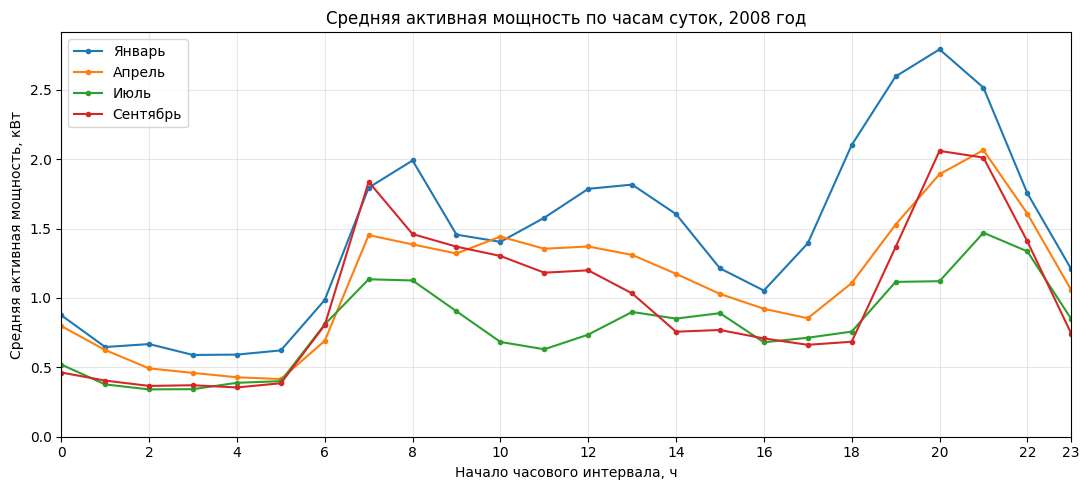

In [8]:
#график
# Подключаем библиотеку для построения графиков.
import matplotlib.pyplot as plt

# Создаём рисунок и систему координат.
# figsize=(11, 5) задаёт размер рисунка в дюймах.
fig, ax = plt.subplots(figsize=(11, 5))

# Названия исследуемых месяцев.
месяцы = ["2008-01", "2008-04", "2008-07", "2008-09"]

# Подписи для легенды.
названия = {
    "2008-01": "Январь",
    "2008-04": "Апрель",
    "2008-07": "Июль",
    "2008-09": "Сентябрь"
}

# Последовательно строим четыре кривые.
for месяц in месяцы:

    ax.plot(
        почасовые_профили["Час"],  # Координаты X
        почасовые_профили[месяц],  # Координаты Y
        marker="o",               # Отмечаем рассчитанные значения
        markersize=3,             # Размер маркеров
        linewidth=1.5,            # Толщина линии
        label=названия[месяц]     # Название в легенде
    )

# Добавляем название графика.
ax.set_title("Средняя активная мощность по часам суток, 2008 год")

# Подписываем горизонтальную ось.
ax.set_xlabel("Начало часового интервала, ч")

# Подписываем вертикальную ось.
ax.set_ylabel("Средняя активная мощность, кВт")

# Устанавливаем диапазон оси X.
ax.set_xlim(0, 23)

# Ось мощности начинается с нуля.
ax.set_ylim(bottom=0)

# Размещаем основные отметки на оси времени.
ax.set_xticks(list(range(0, 24, 2)) + [23])

# Включаем вспомогательную сетку.
ax.grid(True, alpha=0.3)

# Показываем обозначения четырёх месяцев.
ax.legend()

# Автоматически корректируем отступы.
fig.tight_layout()

# Показываем график.
plt.show()


In [9]:
#7
#медианный суточный профиль

import pandas as pd
import numpy as np
import zipfile
from io import BytesIO
from google.colab import files

# Загружаем архив с минутными измерениями шести месяцев.
загрузка = files.upload()

assert len(загрузка) == 1

имя, содержимое = next(iter(загрузка.items()))

# Находим внутри ZIP нужный CSV.
with zipfile.ZipFile(BytesIO(содержимое)) as архив:
    имена = [
        путь for путь in архив.namelist()
        if путь.endswith("04_минутная_энергия.csv")
    ]

    assert len(имена) == 1, "Нужный CSV не найден."

    # Читаем только дату и активную мощность.
    with архив.open(имена[0]) as файл:
        минутные_данные = pd.read_csv(
            файл,
            sep=";",
            usecols=["datetime", "Global_active_power"]
        )

# Приводим столбцы к нужным типам.
минутные_данные["datetime"] = pd.to_datetime(
    минутные_данные["datetime"]
)

минутные_данные["Global_active_power"] = pd.to_numeric(
    минутные_данные["Global_active_power"],
    errors="coerce"
)

# Проверки ранее установленных характеристик данных.
assert len(минутные_данные) == 264960
assert минутные_данные["datetime"].is_unique

assert (
    минутные_данные["Global_active_power"].isna().sum()
    == 8120
)

print("Данные загружены успешно.")
print("Всего строк:", len(минутные_данные))
print(
    "Пропусков:",
    минутные_данные["Global_active_power"].isna().sum()
)


Saving 04_результаты_преобразования.zip to 04_результаты_преобразования.zip
Данные загружены успешно.
Всего строк: 264960
Пропусков: 8120


In [10]:
#8
#медиана и разброс мощности

from pathlib import Path

# Выбранные месяцы для сравнения профилей.
месяцы = ["2008-01", "2008-04", "2008-07", "2008-09"]

# Создаём отдельную рабочую копию.
данные = минутные_данные.copy()

# Получаем обозначение месяца.
данные["Месяц"] = данные["datetime"].dt.strftime("%Y-%m")

# Оставляем четыре исследуемых месяца.
данные = данные[данные["Месяц"].isin(месяцы)].copy()

# Номер минуты суток: от 0 до 1439.
данные["Минута_суток"] = (
    данные["datetime"].dt.hour * 60
    + данные["datetime"].dt.minute
)

# Группируем измерения по месяцу и минуте суток.
группы = данные.groupby(
    ["Месяц", "Минута_суток"]
)["Global_active_power"]

# Рассчитываем характеристики мощности в кВт.
профили = группы.agg(
    Средняя_кВт="mean",
    Медиана_кВт="median",
    Q1_кВт=lambda x: x.quantile(0.25),
    Q3_кВт=lambda x: x.quantile(0.75),
    N="count"
).reset_index()

# Межквартильный размах показывает разброс между днями.
профили["IQR_кВт"] = (
    профили["Q3_кВт"] - профили["Q1_кВт"]
)

# Различие между средним и медианным профилями.
профили["Разница_кВт"] = (
    профили["Средняя_кВт"] - профили["Медиана_кВт"]
).abs()

# Проверяем число точек: 1440 на каждый месяц.
assert len(профили) == 4 * 1440
assert (профили["N"] > 0).all()

# Создаём краткую сравнительную таблицу.
итоги = []

for месяц in месяцы:
    часть = профили[профили["Месяц"] == месяц]

    # Находим пики двух профилей.
    пик_среднего = часть.loc[часть["Средняя_кВт"].idxmax()]
    пик_медианы = часть.loc[часть["Медиана_кВт"].idxmax()]

    итоги.append({
        "Месяц": месяц,
        "Пик среднего, кВт": пик_среднего["Средняя_кВт"],
        "Пик медианы, кВт": пик_медианы["Медиана_кВт"],
        "Время пика среднего": int(
            пик_среднего["Минута_суток"]
        ),
        "Время пика медианы": int(
            пик_медианы["Минута_суток"]
        ),
        "Среднее |различие|, кВт": часть["Разница_кВт"].mean(),
        "Средний IQR, кВт": часть["IQR_кВт"].mean()
    })

сравнение = pd.DataFrame(итоги)

# Переводим номера минут в формат ЧЧ:ММ.
for столбец in ["Время пика среднего", "Время пика медианы"]:
    сравнение[столбец] = сравнение[столбец].apply(
        lambda m: f"{m // 60:02d}:{m % 60:02d}"
    )

print("Сравнение среднего и медианного профилей:")
display(сравнение.round(3))

# Сохраняем результаты отдельно от исходных файлов.
папка = Path("/content/05_медианные_профили")
папка.mkdir(exist_ok=True)

профили.to_csv(
    папка / "05_средний_и_медианный_профили.csv",
    sep=";", index=False, encoding="utf-8-sig"
)

сравнение.to_csv(
    папка / "05_сравнение_профилей.csv",
    sep=";", index=False, encoding="utf-8-sig"
)

# Создаём ZIP для хранения результатов после сброса Colab.
путь_zip = папка / "05_медианные_профили.zip"

with zipfile.ZipFile(
    путь_zip, "w", zipfile.ZIP_DEFLATED
) as архив:
    for файл in папка.glob("*.csv"):
        архив.write(файл, arcname=файл.name)

files.download(str(путь_zip))

print("Расчёты завершены. Результаты сохранены.")


Сравнение среднего и медианного профилей:


,Месяц,"Пик среднего, кВт","Пик медианы, кВт",Время пика среднего,Время пика медианы,"Среднее |различие|, кВт","Средний IQR, кВт"
0,2008-01,3.148,3.016,20:41,20:51,0.225,0.946
1,2008-04,2.386,2.162,21:02,22:21,0.268,0.928
2,2008-07,2.006,1.882,22:01,22:04,0.247,0.737
3,2008-09,2.384,2.318,20:39,06:54,0.192,0.680


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Расчёты завершены. Результаты сохранены.


In [11]:
#распаковка

import pandas as pd
import zipfile
from google.colab import files

# Загружаем готовый архив этапа 5.
загрузка = files.upload()

имя = next(iter(загрузка))

# Читаем подробную таблицу медианных профилей.
with zipfile.ZipFile(имя) as архив:
    with архив.open(
        "05_средний_и_медианный_профили.csv"
    ) as файл:
        профили = pd.read_csv(
            файл,
            sep=";",
            encoding="utf-8-sig"
        )

# Проверяем наличие 4 * 1440 строк.
assert len(профили) == 5760

print("Таблица восстановлена.")
display(профили.head())


Saving 05_медианные_профили.zip to 05_медианные_профили.zip
Таблица восстановлена.


,Месяц,Минута_суток,Средняя_кВт,Медиана_кВт,Q1_кВт,Q3_кВт,N,IQR_кВт,Разница_кВт
0,2008-01,0,0.955935,0.540,0.331,1.379,31,1.048,0.415935
1,2008-01,1,0.945935,0.492,0.329,1.383,31,1.054,0.453935
2,2008-01,2,0.948903,0.622,0.347,1.379,31,1.032,0.326903
3,2008-01,3,1.000516,0.664,0.378,1.375,31,0.997,0.336516
4,2008-01,4,1.011613,0.668,0.382,1.471,31,1.089,0.343613


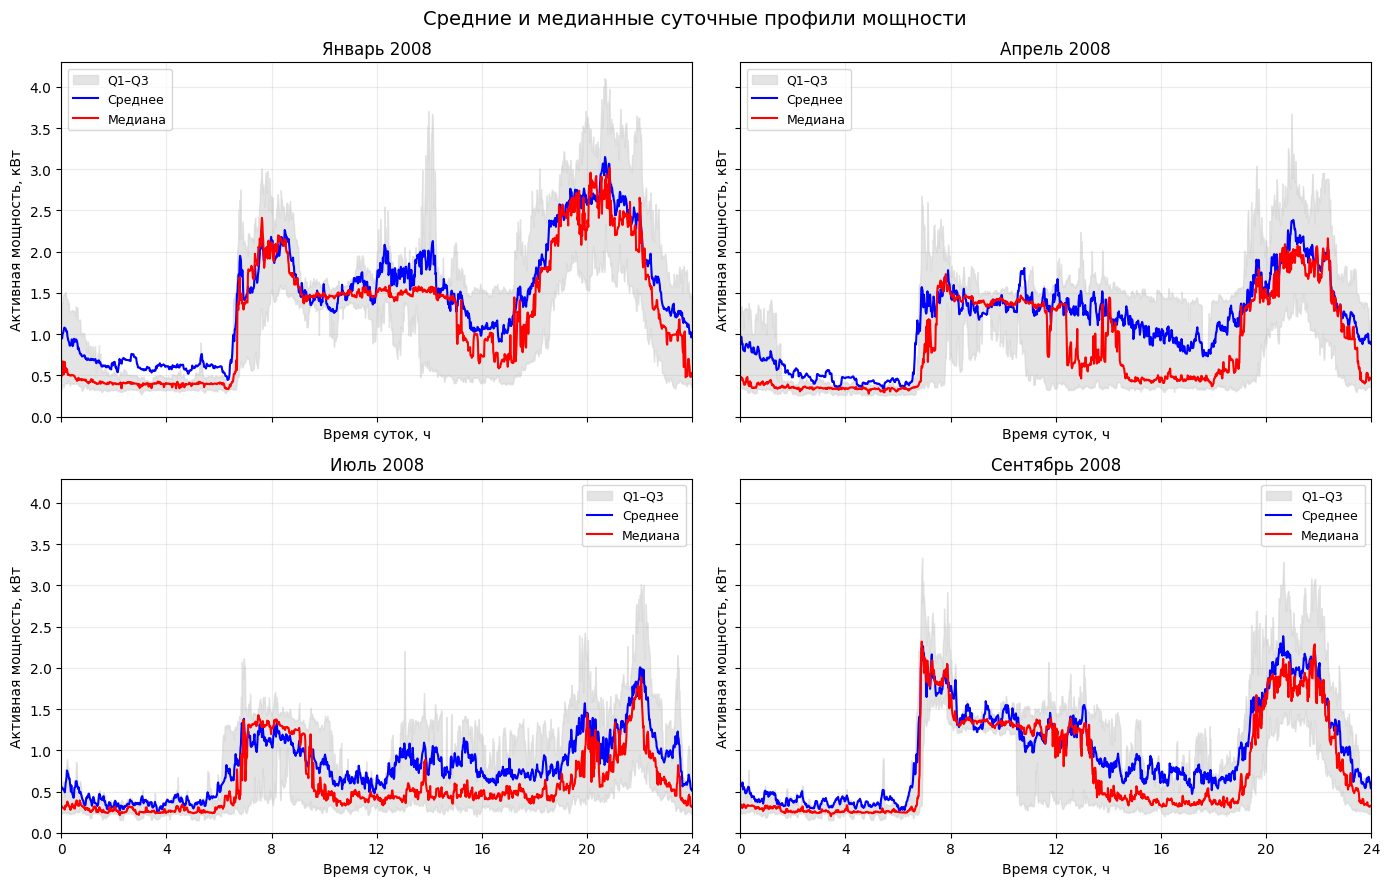

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
#графики среднего, медианы и разброса
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Месяцы и названия графиков.
месяцы = {
    "2008-01": "Январь",
    "2008-04": "Апрель",
    "2008-07": "Июль",
    "2008-09": "Сентябрь"
}

# Создаём четыре графика на одном рисунке.
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    sharex=True,
    sharey=True
)

for ax, (месяц, название) in zip(axes.flat, месяцы.items()):

    # Выбираем результаты нужного месяца.
    часть = профили[профили["Месяц"] == месяц]

    # Переводим номер минуты суток в часы.
    время = часть["Минута_суток"].to_numpy() / 60

    среднее = часть["Средняя_кВт"].to_numpy()
    медиана = часть["Медиана_кВт"].to_numpy()
    q1 = часть["Q1_кВт"].to_numpy()
    q3 = часть["Q3_кВт"].to_numpy()

    # Полоса между первым и третьим квартилями.
    ax.fill_between(
        время, q1, q3,
        color="lightgray",
        alpha=0.6,
        label="Q1–Q3"
    )

    # Средний суточный профиль.
    ax.plot(
        время, среднее,
        color="blue",
        linewidth=1.5,
        label="Среднее"
    )

    # Медианный суточный профиль.
    ax.plot(
        время, медиана,
        color="red",
        linewidth=1.5,
        label="Медиана"
    )

    ax.set_title(название + " 2008")
    ax.set_xlim(0, 24)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.arange(0, 25, 4))
    ax.set_xlabel("Время суток, ч")
    ax.set_ylabel("Активная мощность, кВт")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=9)

# Устанавливаем общий заголовок.
fig.suptitle(
    "Средние и медианные суточные профили мощности",
    fontsize=14
)

# Корректируем расположение графиков.
fig.tight_layout()

# Сохраняем рисунок в двух форматах.
fig.savefig(
    "05_средние_медианные_профили.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "05_средние_медианные_профили.svg",
    bbox_inches="tight"
)

plt.show()

# Скачиваем оба изображения.
files.download("05_средние_медианные_профили.png")
files.download("05_средние_медианные_профили.svg")


In [13]:
#9
#расчет сглаженныъх профилей

import numpy as np
import pandas as pd

# Исследуем четыре выбранных месяца 2008 года.
месяцы = ["2008-01", "2008-04", "2008-07", "2008-09"]

# Два размера окна сглаживания, в минутах.
окна = [15, 61]

# Создаём отдельную копию готовых профилей.
# Исходные измерения не изменяем.
профили_сглаженные = профили.copy(deep=True)


# Функция сглаживания одного суточного профиля.
def сгладить_профиль(значения, окно):

    # Половина ширины окна.
    половина = окно // 2

    # Продолжаем профиль циклически.
    # Последние минуты суток ставим перед первыми,
    # а первые минуты — после последних.
    расширенный = np.concatenate([
        значения[-половина:],
        значения,
        значения[:половина]
    ])

    # Рассчитываем центрированное скользящее среднее.
    сглаженный = (
        pd.Series(расширенный)
        .rolling(
            window=окно,
            center=True,
            min_periods=окно
        )
        .mean()
    )

    # Убираем временно добавленные крайние участки.
    return сглаженный.iloc[
        половина:половина + len(значения)
    ].to_numpy()


# Здесь будут количественные результаты сравнения.
результаты_сглаживания = []

for месяц in месяцы:

    # Выбираем профиль конкретного месяца.
    часть = (
        профили_сглаженные[
            профили_сглаженные["Месяц"] == месяц
        ]
        .sort_values("Минута_суток")
    )

    # Проверяем, что представлены все 1440 минут.
    assert np.array_equal(
        часть["Минута_суток"].to_numpy(),
        np.arange(1440)
    )

    # Проверяем, что для каждой минуты есть наблюдения.
    assert (часть["N"] > 0).all()

    # Берём готовый средний суточный профиль.
    исходный = часть["Средняя_кВт"].to_numpy(dtype=float)

    # Проверяем отсутствие неопределённых значений.
    assert np.isfinite(исходный).all()

    for окно in окна:

        # Сглаживаем профиль.
        сглаженный = сгладить_профиль(исходный, окно)

        # Добавляем результат в отдельный столбец.
        имя_столбца = f"Средняя_{окно}мин_кВт"

        профили_сглаженные.loc[
            часть.index, имя_столбца
        ] = сглаженный

        # Находим исходный и сглаженный максимумы.
        пик_исходный = np.max(исходный)
        пик_сглаженный = np.max(сглаженный)

        # Находим время максимумов в минутах от полуночи.
        время_исходного = int(np.argmax(исходный))
        время_сглаженного = int(np.argmax(сглаженный))

        # Среднее абсолютное отличие двух кривых.
        mae = np.mean(np.abs(исходный - сглаженный))

        # Среднеквадратичное отличие двух кривых.
        rmse = np.sqrt(
            np.mean((исходный - сглаженный) ** 2)
        )

        # Насколько уменьшилась высота максимума.
        снижение_пика = (
            (пик_исходный - пик_сглаженный)
            / пик_исходный * 100
        )

        # Сохраняем показатели данного метода.
        результаты_сглаживания.append({
            "Месяц": месяц,
            "Окно, мин": окно,
            "Исходный пик, кВт": пик_исходный,
            "Сглаженный пик, кВт": пик_сглаженный,
            "Снижение пика, %": снижение_пика,
            "Время исходного пика": (
                f"{время_исходного // 60:02d}:"
                f"{время_исходного % 60:02d}"
            ),
            "Время сглаженного пика": (
                f"{время_сглаженного // 60:02d}:"
                f"{время_сглаженного % 60:02d}"
            ),
            "MAE, кВт": mae,
            "RMSE, кВт": rmse
        })


# Создаём итоговую таблицу сравнения.
таблица_сглаживания = pd.DataFrame(
    результаты_сглаживания
)

# Проверяем, что рассчитано 4 месяца × 2 метода.
assert len(таблица_сглаживания) == 8

print("Сравнение исходных и сглаженных профилей:")
display(таблица_сглаживания.round(4))


Сравнение исходных и сглаженных профилей:


,Месяц,"Окно, мин","Исходный пик, кВт","Сглаженный пик, кВт","Снижение пика, %",Время исходного пика,Время сглаженного пика,"MAE, кВт","RMSE, кВт"
0,2008-01,15,3.1481,3.0228,3.9808,20:41,20:43,0.0388,0.0536
1,2008-01,61,3.1481,2.7909,11.3464,20:41,20:32,0.0787,0.1121
2,2008-04,15,2.3860,2.2860,4.1930,21:02,21:02,0.0397,0.0542
3,2008-04,61,2.3860,2.1223,11.0538,21:02,21:13,0.0730,0.0985
4,2008-07,15,2.0059,1.9136,4.6044,22:01,22:03,0.0417,0.0552
5,2008-07,61,2.0059,1.6606,17.2164,22:01,21:54,0.0673,0.0914
6,2008-09,15,2.3841,2.2271,6.5843,20:39,20:37,0.0409,0.0570
7,2008-09,61,2.3841,2.0871,12.4552,20:39,20:44,0.0806,0.1123


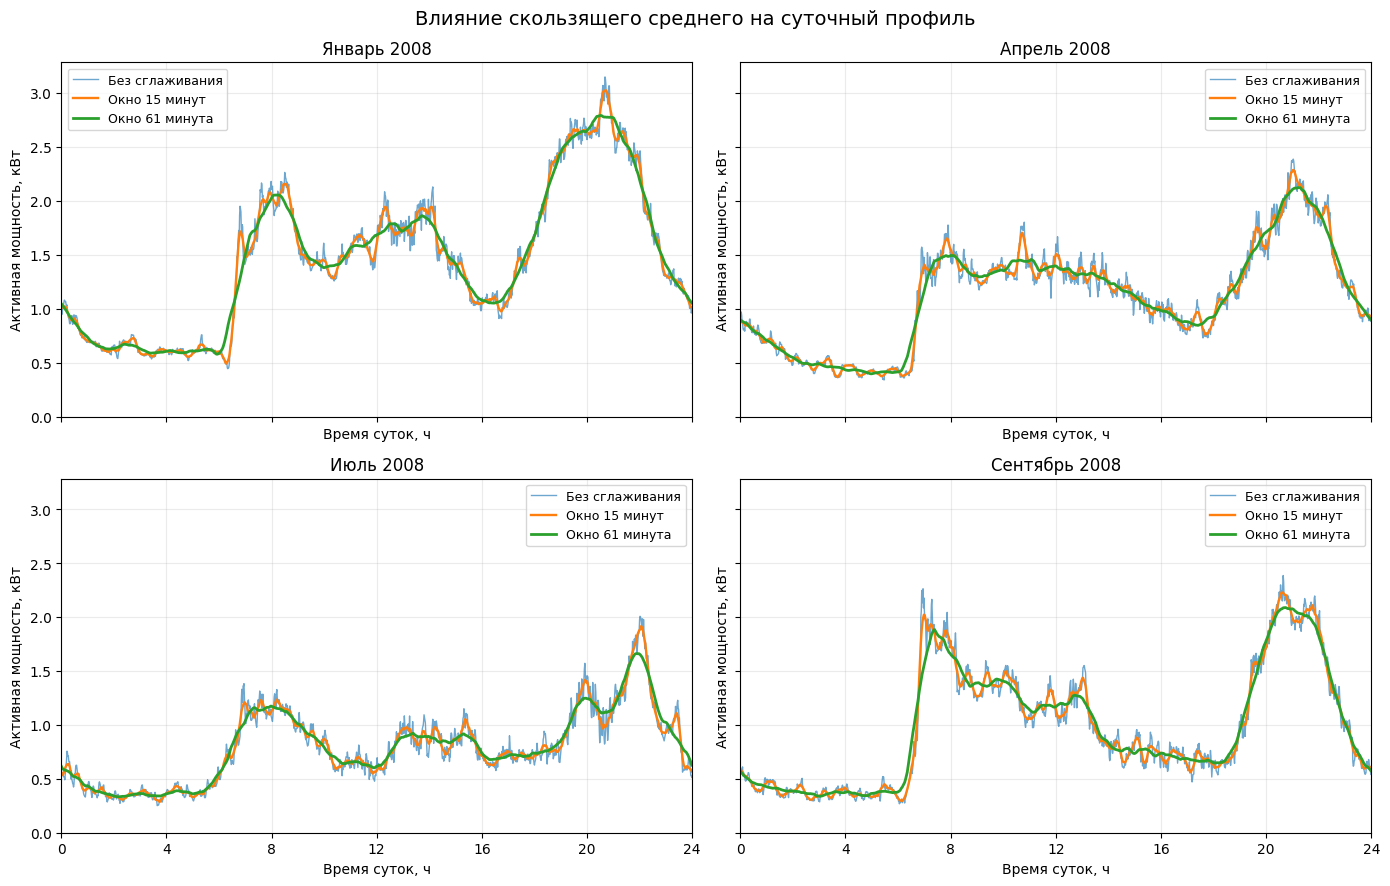

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Графики и таблицы сглаживания сохранены.


In [14]:
#графики

import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
from google.colab import files

# Подписи месяцев.
названия = {
    "2008-01": "Январь",
    "2008-04": "Апрель",
    "2008-07": "Июль",
    "2008-09": "Сентябрь"
}

# Создаём один рисунок с четырьмя графиками.
fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 9),
    sharex=True,
    sharey=True
)

for ax, (месяц, название) in zip(
    axes.flat, названия.items()
):

    # Выбираем нужный месяц и сортируем минуты.
    часть = (
        профили_сглаженные[
            профили_сглаженные["Месяц"] == месяц
        ]
        .sort_values("Минута_суток")
    )

    # Переводим номер минуты в часы.
    время = часть["Минута_суток"] / 60

    # Исходный профиль.
    ax.plot(
        время,
        часть["Средняя_кВт"],
        label="Без сглаживания",
        linewidth=1,
        alpha=0.65
    )

    # Скользящее среднее за 15 минут.
    ax.plot(
        время,
        часть["Средняя_15мин_кВт"],
        label="Окно 15 минут",
        linewidth=1.7
    )

    # Скользящее среднее за 61 минуту.
    ax.plot(
        время,
        часть["Средняя_61мин_кВт"],
        label="Окно 61 минута",
        linewidth=2
    )

    # Оформляем график.
    ax.set_title(название + " 2008")
    ax.set_xlim(0, 24)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.arange(0, 25, 4))
    ax.set_xlabel("Время суток, ч")
    ax.set_ylabel("Активная мощность, кВт")
    ax.grid(True, alpha=0.25)
    ax.legend(fontsize=9)

# Общий заголовок рисунка.
fig.suptitle(
    "Влияние скользящего среднего на суточный профиль",
    fontsize=14
)

fig.tight_layout()

# Создаём отдельную папку для результатов.
папка = Path("/content/05_сглаживание")
папка.mkdir(exist_ok=True)

# Сохраняем рисунок в PNG и SVG.
fig.savefig(
    папка / "05_сравнение_сглаживания.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    папка / "05_сравнение_сглаживания.svg",
    bbox_inches="tight"
)

plt.show()

# Сохраняем все численные результаты.
профили_сглаженные.to_csv(
    папка / "05_сглаженные_профили.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

таблица_сглаживания.to_csv(
    папка / "05_сравнение_сглаживания.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

# Собираем рисунки и таблицы в один ZIP.
имя_архива = "/content/05_сглаживание_результаты.zip"

with zipfile.ZipFile(
    имя_архива,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as архив:

    for файл in папка.iterdir():
        архив.write(файл, arcname=файл.name)

# Скачиваем результаты на компьютер.
files.download(имя_архива)

print("Графики и таблицы сглаживания сохранены.")


In [15]:
#эксперименталиные копии

import pandas as pd
import numpy as np
import zipfile
from io import BytesIO
from google.colab import files

# Если данные остались в памяти Colab, используем их.
# Иначе загружаем архив этапа 4.
if "минутные_данные" not in globals():

    print("Загрузи 04_результаты_преобразования.zip")

    загрузка = files.upload()

    содержимое = next(iter(загрузка.values()))

    with zipfile.ZipFile(BytesIO(содержимое)) as архив:

        имена = [
            имя for имя in архив.namelist()
            if имя.endswith("04_минутная_энергия.csv")
        ]

        assert len(имена) == 1

        with архив.open(имена[0]) as файл:
            минутные_данные = pd.read_csv(
                файл,
                sep=";",
                usecols=["datetime", "Global_active_power"]
            )

# Берём копию только двух необходимых столбцов.
источник = минутные_данные[
    ["datetime", "Global_active_power"]
].copy(deep=True)

# Проверяем типы данных.
источник["datetime"] = pd.to_datetime(
    источник["datetime"]
)

источник["Global_active_power"] = pd.to_numeric(
    источник["Global_active_power"],
    errors="coerce"
)

# Выбираем сентябрь 2008 года.
сентябрь = источник.loc[
    (источник["datetime"] >= "2008-09-01")
    & (источник["datetime"] < "2008-10-01")
].sort_values("datetime").reset_index(drop=True)

# Проверяем, что исходный месяц полный.
assert len(сентябрь) == 43200
assert сентябрь["datetime"].is_unique
assert сентябрь["Global_active_power"].notna().all()

# Вариант 1: случайно удаляем 10% измерений.
случайный = сентябрь.copy(deep=True)

# Фиксируем генератор для воспроизводимости опыта.
генератор = np.random.default_rng(2026)

индексы = генератор.choice(
    len(случайный),
    size=4320,
    replace=False
)

случайный.loc[
    индексы, "Global_active_power"
] = np.nan

# Вариант 2: удаляем трое полных суток.
длительный = сентябрь.copy(deep=True)

маска = (
    (длительный["datetime"] >= "2008-09-15")
    & (длительный["datetime"] < "2008-09-18")
)

assert маска.sum() == 4320

длительный.loc[
    маска, "Global_active_power"
] = np.nan

# Объединяем три варианта исследования.
сценарии = {
    "Полный": сентябрь,
    "Случайный": случайный,
    "Длительный": длительный
}

# Проверяем количество пропусков.
for название, таблица in сценарии.items():

    пропусков = таблица["Global_active_power"].isna().sum()
    полнота = (1 - пропусков / len(таблица)) * 100

    print(
        f"{название}: "
        f"пропусков = {пропусков}, "
        f"полнота = {полнота:.1f}%"
    )


Полный: пропусков = 0, полнота = 100.0%
Случайный: пропусков = 4320, полнота = 90.0%
Длительный: пропусков = 4320, полнота = 90.0%


,Вариант,"Средняя мощность, кВт","Пик профиля, кВт",Время пика,"MAE, кВт","RMSE, кВт"
0,Полный,0.9877,2.3841,20:39,0.0000,0.0000
1,Случайный,0.9908,2.5114,20:38,0.0344,0.0495
2,Длительный,0.9833,2.3071,20:33,0.0294,0.0401


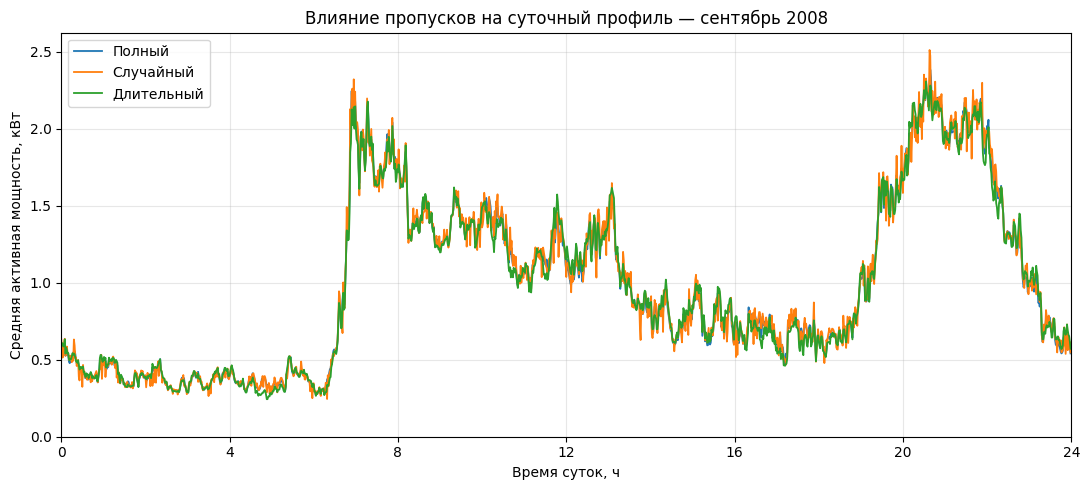

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Эксперимент завершён, результаты сохранены.


In [16]:
#график

import matplotlib.pyplot as plt
from pathlib import Path

# Создаём таблицу из 1440 минут суток.
сравнение_профилей = pd.DataFrame({
    "Минута": np.arange(1440)
})

# Рассчитываем средний профиль для каждого варианта.
for название, таблица in сценарии.items():

    минута = (
        таблица["datetime"].dt.hour * 60
        + таблица["datetime"].dt.minute
    )

    группы = таблица.groupby(
        минута
    )["Global_active_power"]

    # Пропуски NaN не участвуют в вычислении среднего.
    среднее = группы.mean().reindex(range(1440))
    количество = группы.count().reindex(range(1440))

    сравнение_профилей[f"P_{название}_кВт"] = среднее.to_numpy()
    сравнение_профилей[f"N_{название}"] = количество.to_numpy()

# Проверяем, что профиль определён для каждой минуты.
assert not сравнение_профилей.filter(
    like="P_"
).isna().any().any()

# Базовый профиль без удалённых измерений.
эталон = сравнение_профилей["P_Полный_кВт"]

# Создаём сводную таблицу показателей.
результаты = []

for название, таблица in сценарии.items():

    профиль = сравнение_профилей[f"P_{название}_кВт"]

    # Средняя мощность по доступным минутам месяца.
    среднее_месяца = таблица["Global_active_power"].mean()

    # Максимум среднего суточного профиля.
    пик = профиль.max()
    время_пика = int(профиль.idxmax())

    # Отличие от полного исходного профиля.
    mae = np.mean(np.abs(профиль - эталон))
    rmse = np.sqrt(np.mean((профиль - эталон) ** 2))

    результаты.append({
        "Вариант": название,
        "Средняя мощность, кВт": среднее_месяца,
        "Пик профиля, кВт": пик,
        "Время пика": (
            f"{время_пика // 60:02d}:"
            f"{время_пика % 60:02d}"
        ),
        "MAE, кВт": mae,
        "RMSE, кВт": rmse
    })

таблица_влияния = pd.DataFrame(результаты)

display(таблица_влияния.round(4))

# Строим три профиля на одном графике.
fig, ax = plt.subplots(figsize=(11, 5))

время = сравнение_профилей["Минута"] / 60

for название in сценарии:

    ax.plot(
        время,
        сравнение_профилей[f"P_{название}_кВт"],
        linewidth=1.3,
        label=название
    )

ax.set_title("Влияние пропусков на суточный профиль — сентябрь 2008")
ax.set_xlabel("Время суток, ч")
ax.set_ylabel("Средняя активная мощность, кВт")
ax.set_xlim(0, 24)
ax.set_ylim(bottom=0)
ax.set_xticks(np.arange(0, 25, 4))
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

# Сохраняем результаты отдельно от исходных данных.
папка = Path("/content/05_эксперимент_пропуски")
папка.mkdir(exist_ok=True)

fig.savefig(
    папка / "05_влияние_пропусков.png",
    dpi=300,
    bbox_inches="tight"
)

сравнение_профилей.to_csv(
    папка / "05_профили_с_пропусками.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

таблица_влияния.to_csv(
    папка / "05_влияние_пропусков_метрики.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

plt.show()

# Создаём единый архив.
архив_результатов = "/content/05_эксперимент_пропуски.zip"

with zipfile.ZipFile(
    архив_результатов,
    "w",
    zipfile.ZIP_DEFLATED
) as архив:

    for файл in папка.iterdir():
        архив.write(файл, arcname=файл.name)

files.download(архив_результатов)

print("Эксперимент завершён, результаты сохранены.")


In [17]:
#10
#анализ релаьных пропусков

import pandas as pd
import numpy as np
import zipfile
from io import BytesIO
from google.colab import files

# При необходимости восстанавливаем минутные данные.
if "минутные_данные" not in globals():

    print("Загрузи 04_результаты_преобразования.zip")
    загрузка = files.upload()

    assert len(загрузка) == 1

    содержимое = next(iter(загрузка.values()))

    with zipfile.ZipFile(BytesIO(содержимое)) as архив:

        имена = [
            имя for имя in архив.namelist()
            if имя.endswith("04_минутная_энергия.csv")
        ]

        assert len(имена) == 1

        with архив.open(имена[0]) as файл:
            минутные_данные = pd.read_csv(
                файл,
                sep=";",
                usecols=["datetime", "Global_active_power"]
            )

# Создаём копию, не изменяя исходные данные.
данные_август = минутные_данные[
    ["datetime", "Global_active_power"]
].copy(deep=True)

данные_август["datetime"] = pd.to_datetime(
    данные_август["datetime"]
)

данные_август["Global_active_power"] = pd.to_numeric(
    данные_август["Global_active_power"],
    errors="coerce"
)

месяцы = ["2009-08", "2010-08"]

сводка = []
часовые_таблицы = []
суточные_таблицы = []

for месяц in месяцы:

    # Выбираем август нужного года.
    начало = pd.Timestamp(месяц + "-01")
    конец = начало + pd.offsets.MonthBegin(1)

    часть = данные_август.loc[
        (данные_август["datetime"] >= начало)
        & (данные_август["datetime"] < конец)
    ].sort_values("datetime").reset_index(drop=True)

    # В августе 31 день по 1440 минут.
    assert len(часть) == 44640
    assert часть["datetime"].is_unique

    мощность = часть["Global_active_power"]

    # Определяем число отсутствующих измерений.
    пропусков = int(мощность.isna().sum())
    полнота = мощность.count() / len(часть) * 100

    # Группируем значения по часу суток.
    группы_часов = часть.groupby(
        часть["datetime"].dt.hour
    )["Global_active_power"]

    почасовая = группы_часов.agg(
        ["mean", "count", "size"]
    ).reindex(range(24))

    почасовая["Полнота, %"] = (
        почасовая["count"] / почасовая["size"] * 100
    )

    почасовая["Час"] = range(24)
    почасовая["Месяц"] = месяц

    часовые_таблицы.append(почасовая.reset_index(drop=True))

    # Группируем измерения по календарным дням.
    группы_дней = часть.groupby(
        часть["datetime"].dt.day
    )["Global_active_power"]

    посуточная = группы_дней.agg(
        ["count", "size"]
    ).reindex(range(1, 32))

    посуточная["Полнота, %"] = (
        посуточная["count"] / посуточная["size"] * 100
    )

    посуточная["День"] = range(1, 32)
    посуточная["Месяц"] = месяц

    суточные_таблицы.append(посуточная.reset_index(drop=True))

    # Ищем самую длинную последовательность пропусков.
    нет_данных = мощность.isna().to_numpy()

    переходы = np.diff(
        np.r_[False, нет_данных, False].astype(int)
    )

    начала = np.flatnonzero(переходы == 1)
    концы = np.flatnonzero(переходы == -1)

    if len(начала) > 0:

        позиция = np.argmax(концы - начала)
        длина_паузы = int(
            концы[позиция] - начала[позиция]
        )

        начало_паузы = часть.loc[
            начала[позиция], "datetime"
        ]

        конец_паузы = часть.loc[
            концы[позиция] - 1, "datetime"
        ]

        период = (
            f"{начало_паузы:%d.%m.%Y %H:%M} — "
            f"{конец_паузы:%d.%m.%Y %H:%M}"
        )

    else:
        длина_паузы = 0
        период = "Нет пропусков"

    сводка.append({
        "Месяц": месяц,
        "Всего минут": len(часть),
        "Пропусков": пропусков,
        "Полнота, %": полнота,
        "Средняя известная мощность, кВт": мощность.mean(),
        "Самая длинная пауза, мин": длина_паузы,
        "Период самой длинной паузы": период
    })

# Объединяем рассчитанные таблицы.
таблица_реальных_пропусков = pd.DataFrame(сводка)

почасовая_полнота = pd.concat(
    часовые_таблицы, ignore_index=True
)

суточная_полнота = pd.concat(
    суточные_таблицы, ignore_index=True
)

# Проверяем результаты по предыдущему аудиту.
assert dict(zip(
    таблица_реальных_пропусков["Месяц"],
    таблица_реальных_пропусков["Пропусков"]
)) == {"2009-08": 891, "2010-08": 7226}

print("Реальные пропуски:")
display(таблица_реальных_пропусков.round(3))

print("Полнота по календарным дням:")
display(суточная_полнота.round(2))


Реальные пропуски:


,Месяц,Всего минут,Пропусков,"Полнота, %","Средняя известная мощность, кВт","Самая длинная пауза, мин",Период самой длинной паузы
0,2009-08,44640,891,98.004,0.665,891,13.08.2009 05:00 — 13.08.2009 19:50
1,2010-08,44640,7226,83.813,0.591,7226,17.08.2010 21:02 — 22.08.2010 21:27


Полнота по календарным дням:


,count,size,"Полнота, %",День,Месяц
0,1440,1440,100.0,1,2009-08
1,1440,1440,100.0,2,2009-08
2,1440,1440,100.0,3,2009-08
3,1440,1440,100.0,4,2009-08
4,1440,1440,100.0,5,2009-08
...,...,...,...,...,...
57,1440,1440,100.0,27,2010-08
58,1440,1440,100.0,28,2010-08
59,1440,1440,100.0,29,2010-08
60,1440,1440,100.0,30,2010-08


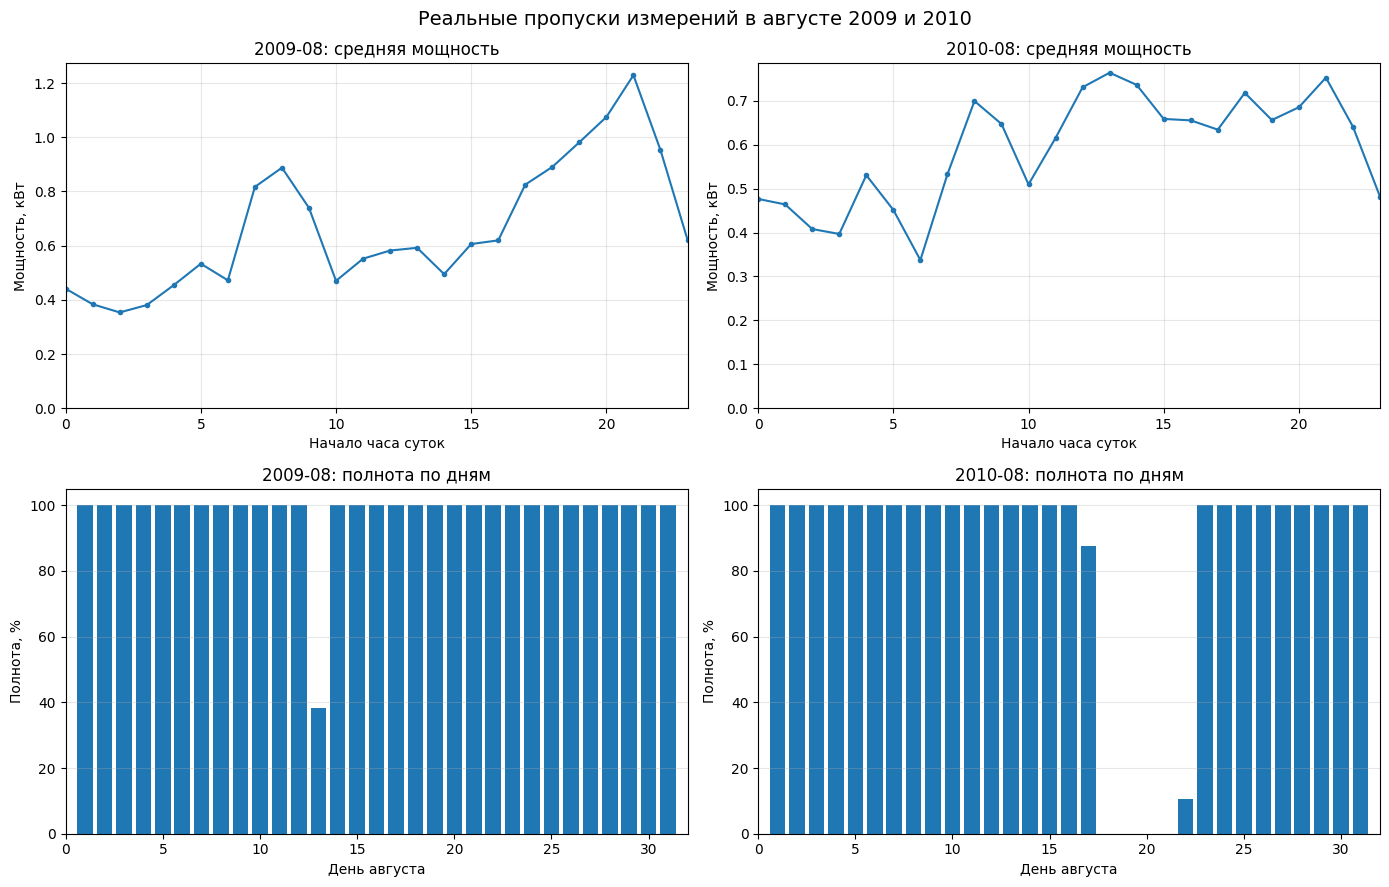

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Анализ реальных пропусков сохранён.


In [18]:

import matplotlib.pyplot as plt
from pathlib import Path

# Создаём рисунок из четырёх графиков.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

месяцы = ["2009-08", "2010-08"]

for i, месяц in enumerate(месяцы):

    часы = почасовая_полнота[
        почасовая_полнота["Месяц"] == месяц
    ]

    дни = суточная_полнота[
        суточная_полнота["Месяц"] == месяц
    ]

    # Верхний график: средняя мощность по часам.
    ax = axes[0, i]

    ax.plot(
        часы["Час"],
        часы["mean"],
        marker="o",
        markersize=3
    )

    ax.set_title(f"{месяц}: средняя мощность")
    ax.set_xlabel("Начало часа суток")
    ax.set_ylabel("Мощность, кВт")
    ax.set_xlim(0, 23)
    ax.set_ylim(bottom=0)
    ax.grid(True, alpha=0.3)

    # Нижний график: полнота каждого дня.
    ax = axes[1, i]

    ax.bar(
        дни["День"],
        дни["Полнота, %"],
        width=0.8
    )

    ax.set_title(f"{месяц}: полнота по дням")
    ax.set_xlabel("День августа")
    ax.set_ylabel("Полнота, %")
    ax.set_xlim(0, 32)
    ax.set_ylim(0, 105)
    ax.grid(True, axis="y", alpha=0.3)

fig.suptitle(
    "Реальные пропуски измерений в августе 2009 и 2010",
    fontsize=14
)

fig.tight_layout()

# Создаём отдельную папку результатов.
папка = Path("/content/05_реальные_пропуски")
папка.mkdir(exist_ok=True)

# Сохраняем график.
fig.savefig(
    папка / "05_реальные_пропуски.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Сохраняем численные результаты.
таблица_реальных_пропусков.to_csv(
    папка / "05_реальные_пропуски_сводка.csv",
    sep=";", index=False, encoding="utf-8-sig"
)

почасовая_полнота.to_csv(
    папка / "05_полнота_по_часам.csv",
    sep=";", index=False, encoding="utf-8-sig"
)

суточная_полнота.to_csv(
    папка / "05_полнота_по_дням.csv",
    sep=";", index=False, encoding="utf-8-sig"
)

# Создаём ZIP со всеми результатами.
имя_архива = "/content/05_реальные_пропуски.zip"

with zipfile.ZipFile(
    имя_архива, "w", zipfile.ZIP_DEFLATED
) as архив:

    for файл in папка.iterdir():
        архив.write(файл, arcname=файл.name)

files.download(имя_архива)

print("Анализ реальных пропусков сохранён.")


In [19]:
#сравнение методов

import pandas as pd
import numpy as np

# Используем таблицу из предыдущего расчёта.
assert "данные_август" in globals()

месяцы = ["2009-08", "2010-08"]

# Здесь будем хранить профили двух методов.
профили_методов = []

# Здесь будут итоговые показатели сравнения.
результаты_методов = []

for месяц in месяцы:

    # Выбираем измерения нужного месяца.
    часть = данные_август.loc[
        данные_август["datetime"].dt.strftime("%Y-%m") == месяц
    ].copy()

    # Определяем календарный день каждого измерения.
    часть["Дата"] = часть["datetime"].dt.date

    # Определяем номер минуты суток.
    часть["Минута"] = (
        часть["datetime"].dt.hour * 60
        + часть["datetime"].dt.minute
    )

    # Считаем количество известных измерений по дням.
    измерений_по_дням = часть.groupby("Дата")[
        "Global_active_power"
    ].count()

    # Находим дни без единого пропуска.
    полные_даты = измерений_по_дням[
        измерений_по_дням == 1440
    ].index

    # Отдельная копия только полных суток.
    полные_сутки = часть[
        часть["Дата"].isin(полные_даты)
    ].copy()

    # Метод 1: все доступные измерения.
    профиль_1 = часть.groupby("Минута")[
        "Global_active_power"
    ].mean().reindex(range(1440))

    # Метод 2: только полностью измеренные дни.
    профиль_2 = полные_сутки.groupby("Минута")[
        "Global_active_power"
    ].mean().reindex(range(1440))

    # Проверяем, достаточно ли данных для обоих профилей.
    assert профиль_1.notna().all()
    assert len(полные_даты) > 0
    assert профиль_2.notna().all()

    # Рассчитываем различие между профилями.
    mae = np.mean(np.abs(профиль_1 - профиль_2))

    # Определяем максимальное абсолютное расхождение.
    max_различие = np.max(np.abs(профиль_1 - профиль_2))

    # Сохраняем подробные профили.
    профили_методов.append(pd.DataFrame({
        "Месяц": месяц,
        "Минута": range(1440),
        "Все доступные, кВт": профиль_1.to_numpy(),
        "Только полные дни, кВт": профиль_2.to_numpy()
    }))

    # Сохраняем характеристики сравнения.
    результаты_методов.append({
        "Месяц": месяц,
        "Полных дней": len(полные_даты),
        "Всего дней": часть["Дата"].nunique(),
        "Средняя мощность, все данные": (
            часть["Global_active_power"].mean()
        ),
        "Средняя мощность, полные дни": (
            полные_сутки["Global_active_power"].mean()
        ),
        "MAE, кВт": mae,
        "Максимальное различие, кВт": max_различие
    })

# Создаём итоговые таблицы.
таблица_сравнения_методов = pd.DataFrame(
    результаты_методов
)

профили_сравнения = pd.concat(
    профили_методов,
    ignore_index=True
)

print("Сравнение способов учёта пропусков:")
display(таблица_сравнения_методов.round(4))


Сравнение способов учёта пропусков:


,Месяц,Полных дней,Всего дней,"Средняя мощность, все данные","Средняя мощность, полные дни","MAE, кВт","Максимальное различие, кВт"
0,2009-08,30,31,0.6646,0.6590,0.0083,0.1905
1,2010-08,25,31,0.5908,0.5842,0.0192,0.1517


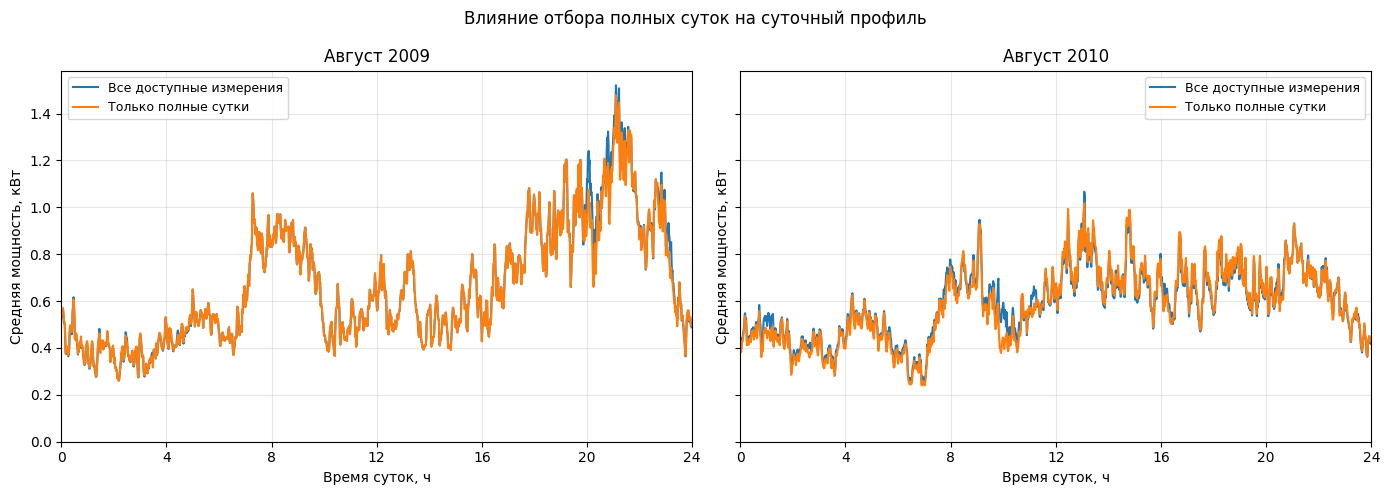

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Результаты сохранены.


In [20]:
#графики

import matplotlib.pyplot as plt
import zipfile
from pathlib import Path
from google.colab import files

# Создаём два графика рядом.
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharex=True,
    sharey=True
)

for ax, месяц in zip(axes, ["2009-08", "2010-08"]):

    # Выбираем данные месяца.
    часть = профили_сравнения[
        профили_сравнения["Месяц"] == месяц
    ]

    время = часть["Минута"] / 60

    # Профиль по всем доступным измерениям.
    ax.plot(
        время,
        часть["Все доступные, кВт"],
        label="Все доступные измерения",
        linewidth=1.5
    )

    # Профиль только по полностью измеренным дням.
    ax.plot(
        время,
        часть["Только полные дни, кВт"],
        label="Только полные сутки",
        linewidth=1.5
    )

    ax.set_title(f"Август {месяц[:4]}")
    ax.set_xlabel("Время суток, ч")
    ax.set_ylabel("Средняя мощность, кВт")
    ax.set_xlim(0, 24)
    ax.set_ylim(bottom=0)
    ax.set_xticks(np.arange(0, 25, 4))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

fig.suptitle(
    "Влияние отбора полных суток на суточный профиль"
)

fig.tight_layout()
plt.show()

# Создаём отдельную папку результатов.
папка = Path("/content/05_сравнение_методов_пропуски")
папка.mkdir(exist_ok=True)

# Сохраняем рисунок.
fig.savefig(
    папка / "05_сравнение_методов.png",
    dpi=300,
    bbox_inches="tight"
)

# Сохраняем обе таблицы.
таблица_сравнения_методов.to_csv(
    папка / "05_сводка_методов.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

профили_сравнения.to_csv(
    папка / "05_профили_методов.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

# Создаём ZIP с результатами.
путь_архива = "/content/05_сравнение_методов_пропуски.zip"

with zipfile.ZipFile(
    путь_архива,
    "w",
    zipfile.ZIP_DEFLATED
) as архив:
    for файл in папка.iterdir():
        архив.write(файл, arcname=файл.name)

files.download(путь_архива)

print("Результаты сохранены.")
